<a href="https://colab.research.google.com/github/Franmira257/Capstone-Project/blob/main/delitos_alumbrado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from itertools import product
import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
import seaborn as sns
from sklearn.ensemble import (
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier



<h1> ⚡ Carga de Datasets y ETL <h1>

In [ ]:
df_delitos = pd.read_csv('Delitos_Diciembre_2025.csv', encoding='utf-8-sig')

In [ ]:
df_delitos

,#,Fecha,Franja Horaria,Tipo,Latitud,Longitud,Barrio,Comuna
0,1564404,2025-12-31,14,Robo,-34.636480,-58.361780,BOCA,COMUNA 4
1,1567221,2025-12-31,14,Amenazas,-34.636651,-58.362197,BOCA,COMUNA 4
2,1567442,2025-12-31,13,Amenazas,-34.637466,-58.366563,BOCA,COMUNA 4
3,1568224,2025-12-31,14,Amenazas,-34.636651,-58.362197,BOCA,COMUNA 4
4,1568265,2025-12-31,5,Hurto,-34.644027,-58.409356,PARQUE PATRICIOS,COMUNA 4
...,...,...,...,...,...,...,...,...
5364,1691141,2025-12-01,11,Hurto,-34.608455,-58.478547,VILLA GRAL. MITRE,COMUNA 11
5365,1691193,2025-12-01,10,Hurto,-34.615754,-58.473571,VILLA GRAL. MITRE,COMUNA 11
5366,1691194,2025-12-01,18,Hurto,-34.612700,-58.495630,VILLA DEL PARQUE,COMUNA 11
5367,1691302,2025-12-01,17,Hurto,-34.612120,-58.497540,VILLA DEL PARQUE,COMUNA 11


In [ ]:
df_luminarias = pd.read_csv('calles-y-avenidas.csv',sep=";", encoding='utf-8-sig')

In [ ]:
df_luminarias

,idexterno,nombredeelemento,comunaid,callenormalizada,lat,lng
0,GLS-23851,Juramento 1190 C13 30P/11/A,13,JURAMENTO,"-34,554512","-58,444189"
1,GLS-60090,Lugones 2284 C12 30P/22/A,12,Lugones,"-34,5724994","-58,4783987"
2,GLS-60091,Lugones 2252 C12 20P/22/A,12,Lugones,"-34,5726705","-58,4781448"
3,GLS-60092,Lugones 2228 C12 10P/22/A,12,Lugones,"-34,5730007","-58,4780988"
4,SL-DUMMY_SC-Al/1418/PAZ GRAL. AV.,PAZ GRAL. AV. 1418 10P/14,12,"PAZ, GRAL. AV.","-34,54087667","-58,47881333"
...,...,...,...,...,...,...
102695,SL-DUMMY_SC-Au/1130/MERCEDES,MERCEDES 1130 20p-11,10,Mercedes,"-34,62396333","-58,48927833"
102696,SL-DUMMY_SC-m/6254/HUBAC,HUBAC 6254 20P / 62,8,Hubac,"-34,667547","-58,48904"
102697,SL-DUMMY_SC-m/3202/LEGUIZAMON MARTINIANO,LEGUIZAMON MARTINIANO 3202 10P / 32,8,"LEGUIZAMON, MARTINIANO","-34,668831","-58,487998"
102698,SL-DUMMY_SC-m/3160/LEGUIZAMON MARTINIANO,LEGUIZAMON MARTINIANO 3160 30P / 31,8,"LEGUIZAMON, MARTINIANO","-34,668352","-58,488583"


<h1>🧹 Limpieza de datasets <h1>

In [ ]:
 # limpieza basica, nos aseguramos que todo sea numerico
df_delitos['Latitud'] = pd.to_numeric(df_delitos['Latitud'], errors='coerce')
df_delitos['Longitud'] = pd.to_numeric(df_delitos['Longitud'], errors='coerce')
df_delitos['Fecha'] = pd.to_datetime(df_delitos['Fecha'], errors='coerce')
df_delitos['Franja Horaria'] = pd.to_numeric(df_delitos['Franja Horaria'], errors='coerce')
df_delitos['es_noche'] = df_delitos['Franja Horaria'].apply(lambda x: 1 if pd.notnull(x) and (x >= 20 or x <= 6) else 0)
df_delitos['Comuna'] = df_delitos['Comuna'].astype(str).str.extract(r'(\d+)')[0]
df_delitos['Comuna'] = pd.to_numeric(df_delitos['Comuna'], errors='coerce')

print(f"Delitos cargados: {len(df_delitos)} registros")


# limpieza basica
# Limpiar coordenadas de luminarias (reemplazar coma por punto y convertir a float)
df_luminarias['lat'] = df_luminarias['lat'].astype(str).str.replace(',', '.').astype(float)
df_luminarias['lng'] = df_luminarias['lng'].astype(str).str.replace(',', '.').astype(float)

# Eliminar nulos si los hay
df_luminarias = df_luminarias.dropna(subset=['lat', 'lng'])

print(f"Luminarias cargadas: {len(df_luminarias)} registros")


Delitos cargados: 5369 registros
Luminarias cargadas: 102700 registros


In [ ]:
# CRUCE ESPACIAL EFICIENTE (KDTree)
# Como un delito no ocurre en la misma coordenada exacta de un poste,
# calculamos la distancia al poste LED más cercano (en metros aproximados).

# Extraer matrices de coordenadas
coords_luminarias = df_luminarias[['lat', 'lng']].values
coords_delitos = df_delitos[['Latitud', 'Longitud']].dropna(subset=['Latitud', 'Longitud']).values

# Construir el árbol espacial
tree = cKDTree(coords_luminarias)

# Consultar la distancia al vecino más cercano (convertido aprox a metros multiplicando por ~111000(los metros que mide un grado de latitud en la Tierra))
distancias, indices = tree.query(df_delitos[['Latitud', 'Longitud']].dropna(subset=['Latitud', 'Longitud']).values, k=1)

# Agregar la distancia en metros al DataFrame de delitos (1 grado lat/lng ~ 111,000 metros)
df_delitos.loc[df_delitos[['Latitud', 'Longitud']].dropna().index, 'distancia_luminaria_cercana_m'] = distancias * 111000

In [ ]:
# CREACIÓN DE VARIABLES NUEVAS (Feature Engineering para el Dashboard)
# Crear columna binaria de horario nocturno (ej: de 20:00 a 06:00 hs)
df_delitos['es_noche'] = df_delitos['Franja Horaria'].apply(lambda x: 1 if (x >= 20 or x <= 6) else 0)

# Ver las primeras filas del dataset unificado y enriquecido
print("\n--- Vista previa del Dataset Unificado ---")
display(df_delitos[['Fecha', 'Franja Horaria', 'Tipo', 'Barrio', 'distancia_luminaria_cercana_m', 'es_noche']].head())


--- Vista previa del Dataset Unificado ---


,Fecha,Franja Horaria,Tipo,Barrio,distancia_luminaria_cercana_m,es_noche
0,2025-12-31,14.0,Robo,BOCA,19.055209,0
1,2025-12-31,14.0,Amenazas,BOCA,5.626746,0
2,2025-12-31,13.0,Amenazas,BOCA,8.470098,0
3,2025-12-31,14.0,Amenazas,BOCA,5.626746,0
4,2025-12-31,5.0,Hurto,PARQUE PATRICIOS,12.591970,1


In [ ]:
# Ver cuántos nulos hay por columna antes de limpiar
print("--- Valores nulos antes de limpiar ---")
print(df_delitos.isnull().sum())

# Eliminar directamente cualquier fila que tenga al menos un nulo
df_delitos = df_delitos.dropna()

print(f"\nTotal de registros limpios con los que nos quedamos: {len(df_delitos)}")

# Guardar el dataset resultante en un nuevo archivo CSV
df_delitos.to_csv('delitos_enriquecidos.csv', index=False, encoding='utf-8-sig')

print("\n¡Dataset limpio y guardado con éxito como 'delitos_enriquecidos.csv'!")

--- Valores nulos antes de limpiar ---
#                                  0
Fecha                              0
Franja Horaria                   124
Tipo                               0
Latitud                            0
Longitud                           0
Barrio                             0
Comuna                             0
es_noche                           0
distancia_luminaria_cercana_m      0
dtype: int64

Total de registros limpios con los que nos quedamos: 5245

¡Dataset limpio y guardado con éxito como 'delitos_enriquecidos.csv'!


<h1> 🕵️ Análisis Estadístico Descriptivo  <h1>

In [ ]:
# 1. Cargar el dataset enriquecido que guardamos antes
df = pd.read_csv('delitos_enriquecidos.csv', encoding='utf-8-sig')

# 2. Información estructural del dataset
print("--- DIMENSIONES Y TIPOS DE DATOS ---")
print(f"Total de registros limpios: {df.shape[0]}")
print(f"Total de variables (columnas): {df.shape[1]}")
print("\n")
print(df.info())

--- DIMENSIONES Y TIPOS DE DATOS ---
Total de registros limpios: 5245
Total de variables (columnas): 10


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5245 entries, 0 to 5244
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   #                              5245 non-null   int64  
 1   Fecha                          5245 non-null   object 
 2   Franja Horaria                 5245 non-null   float64
 3   Tipo                           5245 non-null   object 
 4   Latitud                        5245 non-null   float64
 5   Longitud                       5245 non-null   float64
 6   Barrio                         5245 non-null   object 
 7   Comuna                         5245 non-null   int64  
 8   es_noche                       5245 non-null   int64  
 9   distancia_luminaria_cercana_m  5245 non-null   float64
dtypes: float64(4), int64(3), object(3)
memory usage: 409.9+ KB
Non

In [ ]:
# 3. Estadística descriptiva de variables numéricas
# (Muestra media, desvío estándar, mínimo, cuartiles y máximo)
print("\n--- ESTADÍSTICAS DESCRIPTIVAS (Variables Numéricas) ---")
display(df.describe())


--- ESTADÍSTICAS DESCRIPTIVAS (Variables Numéricas) ---


,#,Franja Horaria,Latitud,Longitud,Comuna,es_noche,distancia_luminaria_cercana_m
count,5.245000e+03,5245.000000,5245.000000,5245.000000,5245.000000,5245.000000,5245.000000
mean,1.628568e+06,13.407626,-34.611354,-58.436872,7.535367,0.356149,20.121193
std,3.755881e+04,6.348698,0.030958,0.043572,4.649555,0.478906,32.850088
min,1.561119e+06,0.000000,-34.698040,-58.529670,1.000000,0.000000,0.011100
25%,1.596097e+06,9.000000,-34.631715,-58.469645,3.000000,0.000000,9.114568
50%,1.628516e+06,14.000000,-34.610504,-58.435767,7.000000,0.000000,13.335995
75%,1.659897e+06,19.000000,-34.591224,-58.400564,12.000000,1.000000,18.106005
max,1.693823e+06,23.000000,-34.535784,-58.352780,15.000000,1.000000,429.162778


In [ ]:
# 4. Análisis de frecuencias categóricas principales
print("\n--- TOP 5 DE TIPOS DE DELITOS MÁS FRECUENTES ---")
print(df['Tipo'].value_counts().head(5))

print("\n--- TOP 5 DE COMUNAS CON MÁS REGISTROS ---")
print(df['Comuna'].value_counts().head(5))

print("\n--- DISTRIBUCIÓN HORARIA (Día vs Noche 'es_noche') ---")
print(df['es_noche'].value_counts(normalize=True) * 100) # Porcentaje


--- TOP 5 DE TIPOS DE DELITOS MÁS FRECUENTES ---
Tipo
Hurto              3729
Amenazas            812
Robo                338
Hurto automotor     337
Robo automotor       18
Name: count, dtype: int64

--- TOP 5 DE COMUNAS CON MÁS REGISTROS ---
Comuna
1     728
4     465
14    428
3     414
7     360
Name: count, dtype: int64

--- DISTRIBUCIÓN HORARIA (Día vs Noche 'es_noche') ---
es_noche
0    64.385129
1    35.614871
Name: proportion, dtype: float64


### 📊 Gráficos


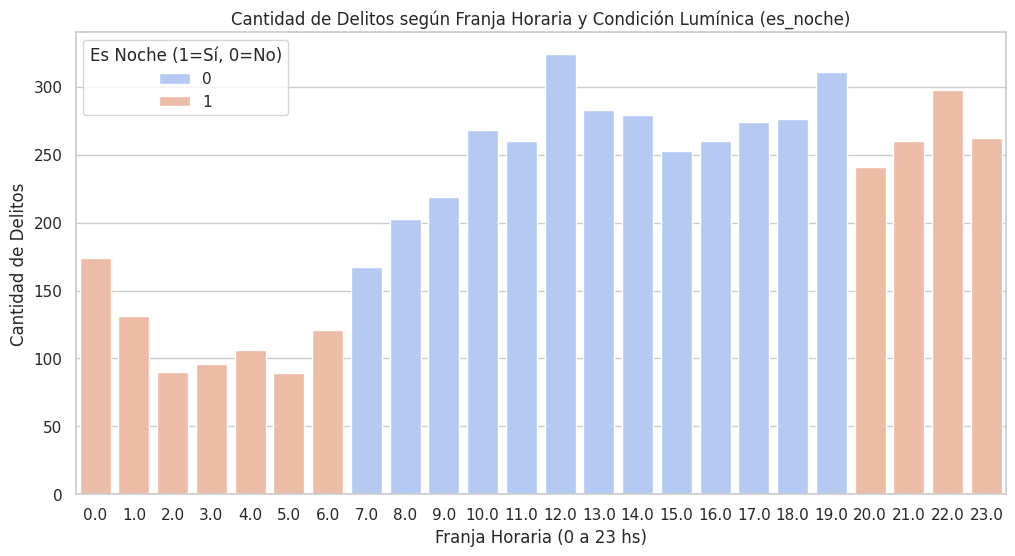

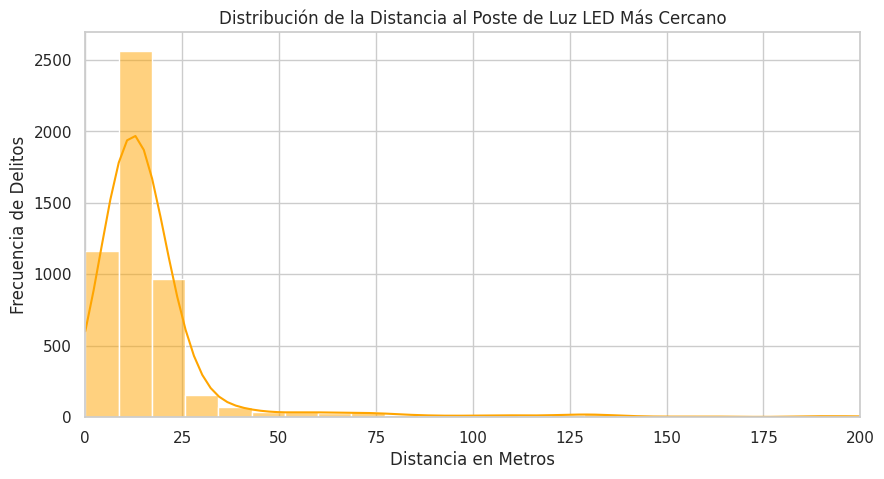

In [ ]:
# 5. GENERACIÓN DE GRÁFICOS PARA EL DASHBOARD (EDA Visual)

# Configuración estética de los gráficos
sns.set_theme(style="whitegrid")

# Gráfico A: Delitos por Franja Horaria diferenciando si es de noche
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='Franja Horaria', hue='es_noche', palette='coolwarm')
plt.title('Cantidad de Delitos según Franja Horaria y Condición Lumínica (es_noche)')
plt.xlabel('Franja Horaria (0 a 23 hs)')
plt.ylabel('Cantidad de Delitos')
plt.legend(title='Es Noche (1=Sí, 0=No)')
plt.show()

# Gráfico B: Distancia a la luminaria más cercana (Histograma)
plt.figure(figsize=(10, 5))
sns.histplot(df['distancia_luminaria_cercana_m'], bins=50, color='orange', kde=True)
plt.title('Distribución de la Distancia al Poste de Luz LED Más Cercano')
plt.xlabel('Distancia en Metros')
plt.ylabel('Frecuencia de Delitos')
plt.xlim(0, 200) # Acotamos para ver mejor el grueso de los datos cerca de las esquinas
plt.show()

In [ ]:
df

,#,Fecha,Franja Horaria,Tipo,Latitud,Longitud,Barrio,Comuna,es_noche,distancia_luminaria_cercana_m
0,1564404,2025-12-31,14.0,Robo,-34.636480,-58.361780,BOCA,4,0,19.055209
1,1567221,2025-12-31,14.0,Amenazas,-34.636651,-58.362197,BOCA,4,0,5.626746
2,1567442,2025-12-31,13.0,Amenazas,-34.637466,-58.366563,BOCA,4,0,8.470098
3,1568224,2025-12-31,14.0,Amenazas,-34.636651,-58.362197,BOCA,4,0,5.626746
4,1568265,2025-12-31,5.0,Hurto,-34.644027,-58.409356,PARQUE PATRICIOS,4,1,12.591970
...,...,...,...,...,...,...,...,...,...,...
5240,1691141,2025-12-01,11.0,Hurto,-34.608455,-58.478547,VILLA GRAL. MITRE,11,0,8.565928
5241,1691193,2025-12-01,10.0,Hurto,-34.615754,-58.473571,VILLA GRAL. MITRE,11,0,18.006911
5242,1691194,2025-12-01,18.0,Hurto,-34.612700,-58.495630,VILLA DEL PARQUE,11,0,19.637905
5243,1691302,2025-12-01,17.0,Hurto,-34.612120,-58.497540,VILLA DEL PARQUE,11,0,16.637246


<h1>Matriz de Correlacion<h1>

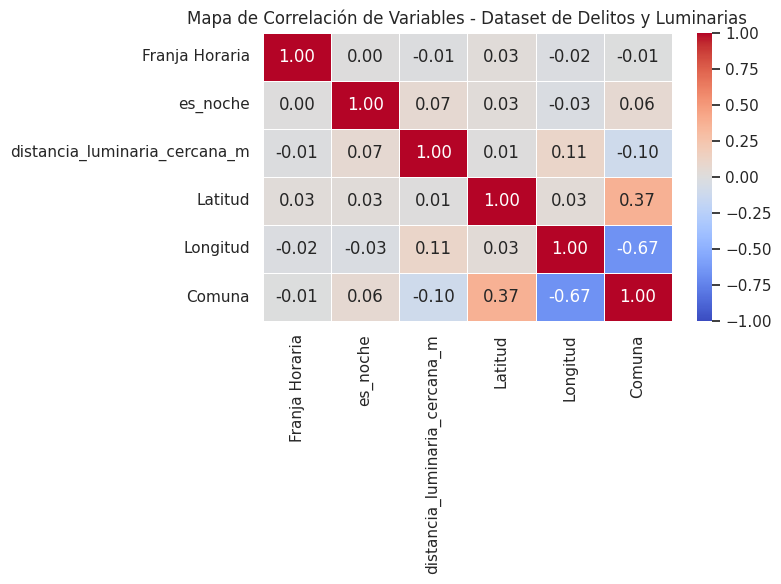

In [ ]:
# Seleccionar solo las columnas numéricas relevantes para la correlación
# (Si tienes columnas de texto, Pandas las ignora automáticamente o podemos filtrar las clave)
columnas_numericas = ['Franja Horaria', 'es_noche', 'distancia_luminaria_cercana_m', 'Latitud', 'Longitud','Comuna']

# Filtrar el dataframe asegurando que solo tome esas columnas si existen
df_corr = df[[col for col in columnas_numericas if col in df.columns]]

# Calcular la matriz de correlación (método de Pearson)
matriz_correlacion = df_corr.corr()

# Generar el Mapa de Calor (Heatmap) para el Dashboard
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Mapa de Correlación de Variables - Dataset de Delitos y Luminarias')
plt.tight_layout()
plt.show()

 <h1>🔎Muestreos<h1>

In [ ]:
# Definir el tamaño de la muestra exacto de 2000 muestras
N = len(df)
n = 2000

print(f"Tamaño de la población (N): {N}")
print(f"Tamaño de muestra exacto (n): {n}\n")

# 1. Muestreo Aleatorio Simple (MAS) - Selección al azar
df_mas = df.sample(n=n, random_state=42).reset_index(drop=True)
print(f"Muestreo Aleatorio Simple extraído: {len(df_mas)} registros.")

# 2. Muestreo Sistemático - Selección con intervalo y punto de inicio aleatorio
k = N // n  # Intervalo de selección
start_index = np.random.randint(0, k)  # Punto de inicio aleatorio en el primer intervalo
systematic_indices = np.arange(start_index, N, step=k)[:n]
df_sistematico = df.iloc[systematic_indices].reset_index(drop=True)
print(f"Muestreo Sistemático extraído: {len(df_sistematico)} registros (Intervalo k = {k}, Inicio = {start_index}).\n")

# 3. Muestreo Estratificado
tamanos = (df['Tipo'].value_counts(normalize=True) * n).round().astype(int)
tamanos.iloc[0] += n - tamanos.sum()  # Ajuste de 1 fila para clavar en 2000 exactos °°°°

df_estratificado = pd.concat([
    df[df['Tipo'] == cat].sample(n=cant, random_state=42)
    for cat, cant in tamanos.items()
]).reset_index(drop=True)
print(f"Muestreo Estratificado extraído: {len(df_estratificado)} registros.")

# 4. Muestreo por Conglomerados - Clusters

np.random.seed(42)
comunas_azar = np.random.permutation(df['Comuna'].unique())
comunas_elegidas = []
total_filas = 0
for c in comunas_azar:
    if total_filas < n:
        comunas_elegidas.append(int(c))
        total_filas += len(df[df['Comuna'] == c])

df_conglomerados = df[df['Comuna'].isin(comunas_elegidas)].reset_index(drop=True)
print(f"Muestreo por Conglomerados extraído: {len(df_conglomerados)} registros (Comunas: {sorted(comunas_elegidas)}).\n")

# 5. Comparación Estadística
metrics = ['Franja Horaria', 'distancia_luminaria_cercana_m', 'Comuna', 'es_noche']

# Construimos un dataframe comparativo con las medias de cada variable
comparativa = pd.DataFrame({
    'Población Original': df[metrics].mean(),
    'Muestra Simple (MAS)': df_mas[metrics].mean(),
    'Muestra Sistemática': df_sistematico[metrics].mean(),
    'Muestra Estratificada': df_estratificado[metrics].mean(),
    'Muestra Conglomerados': df_conglomerados[metrics].mean()
})

print("--- COMPARATIVAS DE MEDIAS EN LAS MUESTRAS ---")
display(comparativa)

Tamaño de la población (N): 5245
Tamaño de muestra exacto (n): 2000

Muestreo Aleatorio Simple extraído: 2000 registros.
Muestreo Sistemático extraído: 2000 registros (Intervalo k = 2, Inicio = 0).

Muestreo Estratificado extraído: 2000 registros.
Muestreo por Conglomerados extraído: 2002 registros (Comunas: [3, 4, 8, 9, 10, 12]).

--- COMPARATIVAS DE MEDIAS EN LAS MUESTRAS ---


,Población Original,Muestra Simple (MAS),Muestra Sistemática,Muestra Estratificada,Muestra Conglomerados
Franja Horaria,13.407626,13.327500,13.537000,13.38450,13.398601
distancia_luminaria_cercana_m,20.121193,19.750512,20.713401,19.27891,19.599990
Comuna,7.535367,7.623500,7.488000,7.64800,7.004995
es_noche,0.356149,0.339500,0.369500,0.35850,0.351648


#### 📝 Análisis e Interpretación del Muestreo (Muestra objetivo: 2000 registros)

Este análisis compara las métricas estadísticas clave obtenidas mediante cuatro métodos de muestreo (aleatorio simple, sistemático, estratificado y por conglomerados) con un tamaño objetivo de $n = 2000$ registros frente a la población original de delitos ($N = 5245$ registros).

---

#### 1. Estructura de las Muestras:
* **Población ($N = 5245$)**: Es el dataset completo con el que trabajamos.
* **Muestra objetivo ($n = 2000$)**: Equivale a aproximadamente el $38.1\%$ de la población, una fracción de muestreo alta que favorece la precisión de las estimaciones.
* **Muestreo Aleatorio Simple (MAS)**: Selección puramente probabilística sin reposición. Tamaño obtenido: $2000$.
* **Muestreo Sistemático ($k = 2$)**: Se toma un registro de por medio a partir de un punto de inicio aleatorio entre los índices $0$ y $1$ (en esta corrida comenzó en el índice $1$). Tamaño obtenido: $2000$.
* **Muestreo Estratificado (por tipo de delito)**: Asignación proporcional al peso de cada tipo de delito en la población. El redondeo de las cuotas se compensó ajustando un registro en el estrato mayoritario. Tamaño obtenido: $2000$.
* **Muestreo por Conglomerados (por comuna)**: Se sortean comunas completas hasta alcanzar el tamaño objetivo. Resultaron seleccionadas las comunas $3, 4, 8, 9, 10$ y $12$. Como el tamaño depende del de las comunas elegidas, se obtuvieron $2002$ registros.


---


#### 2. Interpretación de las Medias comparadas:

* **Franja Horaria**: La media poblacional es de 13.41 (aprox. 13:24 hs). Los cuatro métodos quedan a menos de 5 minutos de la realidad: MAS y sistemático a unos 5 minutos, estratificado a ~1,4 minutos y conglomerados a ~0,5 minutos.
* **Distancia a Luminaria Cercana (m)**: La distancia promedio de un delito a un poste LED es de 20.12 metros. Las cuatro muestras la subestiman levemente, con diferencias de entre $0.4$ m (MAS) y $0.9$ m (sistemático), es decir, entre un $2\%$ y un $5\%$ del valor poblacional.
* **Comuna**: La media se mantiene similar en MAS ($7.62$), sistemático ($7.46$) y estratificado ($7.65$) frente a la población ($7.54$). En conglomerados baja a $7.00$, algo esperable porque la muestra proviene de solo seis comunas. Al ser una variable categórica, esta media se usa solo como referencia descriptiva.
* **es_noche (Proporción de delitos nocturnos)**: En la población, el 35.61 % de los incidentes son nocturnos. Las diferencias van de $0.2$ a $1.7$ puntos porcentuales: estratificado (+0.2), sistemático (+0.4), conglomerados (−0.5) y MAS (−1.7), este último el más alejado pero dentro de lo esperable por azar muestral.
---

#### 💡 Conclusión

Con una fracción de muestreo cercana al $38\%$, los cuatro métodos reproducen de forma satisfactoria las medias poblacionales de las variables de interés (franja horaria, distancia a la luminaria y proporción de delitos nocturnos), con diferencias pequeñas en todos los casos. A pesar de ello, se sugiere el uso del **MUESTREO ESTRATIFICADO** porque evita subrepresentar a los delitos menos frecuentes y/o las comunas menos pobladas.

Entre las particularidades de cada método:

* **Estratificado**: además de ubicarse entre los más cercanos a la población en franja horaria y proporción nocturna, garantiza por construcción la misma distribución de tipos de delito que la población.
* **MAS**: es el método de referencia, sin sesgos de selección. Su mayor desvío se dio en la proporción nocturna ($-1.7$ p.p.), atribuible al azar de una única extracción.
* **Sistemático**: con $k = 2$ la selección recorre los registros de a pasos de dos y no llega al final de la base, por lo que su validez depende de que el orden de los registros no esté asociado a las variables de estudio.
* **Conglomerados**: reproduce bien las medias de las variables analizadas, pero concentra la muestra en seis comunas, por lo que conviene usarlo con cautela si se busca inferir sobre la distribución territorial. Su ventaja es operativa (menor costo de relevamiento) más que de precisión.

*Nota: el tamaño de $2002$ en conglomerados se debe a que el tamaño final depende del de las comunas seleccionadas, por lo que $n = 2000$ es un valor objetivo y no exacto. Los resultados corresponden a una única extracción de cada método; otra semilla podría arrojar diferencias distintas entre ellos.*

<h1>Entrenamiento de modelo y seleccion de features<h1>

## 🛠️ Preparacion de datos para entrenar el modelo

In [ ]:
df_base = (df_delitos if 'df_delitos' in globals() else df).copy()

# Normalizamos 'Comuna' si viene como texto (ej. 'COMUNA 4')
if df_base['Comuna'].dtype == object or pd.api.types.is_string_dtype(
    df_base['Comuna']
):
  df_base['Comuna'] = (
      df_base['Comuna']
      .astype(str)
      .str.extract(r'(\d+)')
      .astype(float)
  )

features = [
    'Comuna',
    'Latitud',
    'Longitud',
    'Franja Horaria',
    'distancia_luminaria_cercana_m',
]
target = 'es_hurto'

df_base[target] = (df_base['Tipo'] == 'Hurto').astype(int)

datos_modelo = df_base[features + [target]].dropna().copy()
X_train = datos_modelo[features]
y_train = datos_modelo[target]

## 🆚🔎 Comparación de modelos en búsqueda aleatoria

In [ ]:
dict_classifiers = {
    'Random Forest': RandomForestClassifier(
        class_weight='balanced', random_state=42, n_jobs=-1
    ),
    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced', random_state=42
    ),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(
        class_weight='balanced', random_state=42
    ),
}

param_grid_classifiers = {
    'Random Forest': {
        'n_estimators': [150, 300],
        'max_depth': [10, 15, 25, None],
        'min_samples_split': [2, 10, 20],
        'min_samples_leaf': [2, 5, 15],
    },
    'Decision Tree': {
        'max_depth': [5, 10, 15, 25],
        'min_samples_split': [5, 15, 30],
        'min_samples_leaf': [5, 15, 30],
    },
    'Gradient Boosting': {
        'n_estimators': [100, 200],
        'learning_rate': [0.03, 0.05, 0.1],
        'max_depth': [3, 5, 7],
        'min_samples_leaf': [5, 15, 30],
    },
    'Hist Gradient Boosting': {
        'max_iter': [150, 300],
        'learning_rate': [0.03, 0.05, 0.1],
        'max_depth': [5, 10, None],
        'min_samples_leaf': [10, 20, 50],
    },
}

scoring_metrics = {
    'roc_auc': 'roc_auc',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
}


def comparar_modelos(X, y, n_iter=4, cv_splits=3, verbose=True):
  cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=42)
  filas = []
  modelos_entrenados = {}

  for nombre, clf in dict_classifiers.items():
    # Evitamos doble paralelismo anidado si el estimador ya usa n_jobs=-1
    search_n_jobs = 1 if nombre == 'Random Forest' else -1

    search = RandomizedSearchCV(
        estimator=clf,
        param_distributions=param_grid_classifiers[nombre],
        n_iter=n_iter,
        cv=cv,
        scoring=scoring_metrics,
        refit='roc_auc',
        random_state=42,
        n_jobs=search_n_jobs,
    )

    t_start = time.perf_counter()
    search.fit(X, y)
    tiempo_s = round(time.perf_counter() - t_start, 2)

    idx = search.best_index_
    cv_res = search.cv_results_
    modelos_entrenados[nombre] = search.best_estimator_

    filas.append({
        'Modelo': nombre,
        'ROC-AUC': round(cv_res['mean_test_roc_auc'][idx], 4),
        'Precision': round(cv_res['mean_test_precision'][idx], 4),
        'Recall': round(cv_res['mean_test_recall'][idx], 4),
        'F1-Score': round(cv_res['mean_test_f1'][idx], 4),
        'Tiempo (s)': tiempo_s,
    })

    if verbose:
      print(f'Evaluado: {nombre} ({tiempo_s}s) | Best AUC: {filas[-1]["ROC-AUC"]}')

  df_tabla = (
      pd.DataFrame(filas)
      .sort_values(by='ROC-AUC', ascending=False)
      .reset_index(drop=True)
  )
  return df_tabla, modelos_entrenados


tabla_modelos, modelos_entrenados = comparar_modelos(X_train, y_train)
display(tabla_modelos)

Evaluado: Random Forest (17.37s) | Best AUC: 0.6706
Evaluado: Decision Tree (5.15s) | Best AUC: 0.6298
Evaluado: Gradient Boosting (25.34s) | Best AUC: 0.6541
Evaluado: Hist Gradient Boosting (4.23s) | Best AUC: 0.6614


,Modelo,ROC-AUC,Precision,Recall,F1-Score,Tiempo (s)
0,Random Forest,0.6706,0.7711,0.8061,0.7882,17.37
1,Hist Gradient Boosting,0.6614,0.7794,0.7047,0.7401,4.23
2,Gradient Boosting,0.6541,0.7402,0.9434,0.8295,25.34
3,Decision Tree,0.6298,0.7845,0.5741,0.6629,5.15


## 💾🥒 Selección y guardado de modelo **(.pickle)**

In [ ]:
mejor_nombre = tabla_modelos.loc[0, 'Modelo']
mejor_modelo = modelos_entrenados[mejor_nombre]
print(f'\nModelo seleccionado automáticamente: {mejor_nombre}')

modelo_rf_apify = modelos_entrenados['Random Forest']
payload_apify = {
    'model': modelo_rf_apify,
    'features': features,
    'target': target,
}
with open('modelo_hurto_rf.pickle', 'wb') as f:
  pickle.dump(payload_apify, f)
print('Archivo guardado para Apify: modelo_hurto_rf.pickle')


Modelo seleccionado automáticamente: Random Forest
Archivo guardado para Apify: modelo_hurto_rf.pickle


## ⚙️📝 BATCH INFERENCE: Grilla Futura

Construimos una grilla de puntos geográficos (5×5 por comuna) combinada con las 24 franjas horarias, de manera que el modelo entrenado predice en una sola pasada la probabilidad de hurto para cada combinación lugar-hora.

**🤔 ¿Por qué una grilla?**

La grilla nos permite estimar el riesgo en zonas y horarios sin registros históricos y generar un mapa de calor parejo de toda la ciudad.

In [ ]:
def construir_grilla_futura(df, n_lat=5, n_lon=5):
  # Agrupamos una sola vez por comuna para obtener rangos y promedio de luminaria
  resumen_comunas = (
      df.dropna(subset=['Comuna', 'Latitud', 'Longitud'])
      .groupby('Comuna', as_index=False)
      .agg(
          lat_min=('Latitud', 'min'),
          lat_max=('Latitud', 'max'),
          lon_min=('Longitud', 'min'),
          lon_max=('Longitud', 'max'),
          lum_promedio=('distancia_luminaria_cercana_m', 'mean'),
      )
  )

  franjas_horarias = np.arange(0, 24)
  bloques = []

  for row in resumen_comunas.itertuples(index=False):
    lats = np.linspace(row.lat_min, row.lat_max, n_lat)
    lons = np.linspace(row.lon_min, row.lon_max, n_lon)

    grid = np.array(list(product(lats, lons, franjas_horarias)))
    df_bloque = pd.DataFrame(
        grid, columns=['Latitud', 'Longitud', 'Franja Horaria']
    )
    df_bloque['Comuna'] = row.Comuna
    df_bloque['distancia_luminaria_cercana_m'] = row.lum_promedio
    bloques.append(df_bloque)

  return pd.concat(bloques, ignore_index=True)


df_futuro = construir_grilla_futura(df_base, n_lat=5, n_lon=5)
df_futuro['probabilidad_hurto_futura'] = mejor_modelo.predict_proba(
    df_futuro[features]
)[:, 1]

df_futuro.to_csv('probabilidad_delitos.csv', index=False, encoding='utf-8-sig')
print(
    f'Listo! CSV generado con {len(df_futuro)} filas usando: {mejor_nombre}'
)

Listo! CSV generado con 9000 filas usando: Random Forest


# 🔮🎯 Predicción utilizando Random Forest

In [ ]:
df_futuro

,Latitud,Longitud,Franja Horaria,Comuna,distancia_luminaria_cercana_m,probabilidad_hurto_futura
0,-34.633338,-58.392757,0.0,1,35.976096,0.557504
1,-34.633338,-58.392757,1.0,1,35.976096,0.526204
2,-34.633338,-58.392757,2.0,1,35.976096,0.568621
3,-34.633338,-58.392757,3.0,1,35.976096,0.590700
4,-34.633338,-58.392757,4.0,1,35.976096,0.579987
...,...,...,...,...,...,...
8995,-34.575166,-58.424846,19.0,15,13.086947,0.736747
8996,-34.575166,-58.424846,20.0,15,13.086947,0.756425
8997,-34.575166,-58.424846,21.0,15,13.086947,0.720789
8998,-34.575166,-58.424846,22.0,15,13.086947,0.712092


El modelo nos dio la probabilidad de hurto de cada lugar donde ocurrió un hecho el mes pasado para el mes entrante. Es perfecto para aplicarlo al **Dashboard del mapa de calor de la ciudad**.